# 06 // Beta diversity analysis

This notebook:
- Performs beta diversity analysis 

**Inputs**:
- Feature Tables: 
    - `results/04_taxonomy/bracken_table_G.qza` [genus-level]
    - `results/04_taxonomy/bracken_table_S.qza` [species-level]
- Taxonomic Classification: 
    - `results/04_taxonomy/bracken_taxonomy_G.qza` [genus-level]
    - `results/04_taxonomy/bracken_taxonomy_S.qza` [species-level]

**Outputs** (they go into `results/06_beta_diversity`):
- `alpha_rarefection.qzv`

**Types of Analysis**

- Distance And Dissimilarity Metrics 

|Analysis Framework|Considers Abunance|Considers Phylogeny|
|---|---|---|
|[Jaccard Index](#jaccard-analysis)| No | No |
|Bray-Curtis Dissimilarity|Yes |Yes|
|Unweighted UniFrac | No | Yes|
|Weighted UniFrac| Yes | Yes |

As we do not have a phylogenetic tree, only the first two analysis are performed

- Group-Level Hypothesis Testing 

    - PERMANOVA
    - PERMDIST
    - ANOSIM


## Setup

In [1]:
# IMPORT PACKAGES
import os
import pandas as pd
import qiime2 as q2
import subprocess
from skbio import OrdinationResults
from qiime2 import Visualization
from qiime2 import Artifact
from seaborn import scatterplot
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
rerun_analyses = False
visualise = False

In [3]:
# Specify Directories for Analysis Pipelines 
result_dir = '../results'
taxa_dir = '../results/04_taxonomy'
beta_dir = '../results/06_beta_diversity'
root_dir = '..'

## 1. Load Metadata and Inspect Genus and Species-Level Feature Tables

In [4]:
# Extract Metadata 
metadata_df = pd.read_csv(f'{root_dir}/african_gut_microbiomes_metadata.tsv', delimiter = '\t', index_col = 0)

#### **GENUS-LEVEL**

In [5]:
# INSPECT FEATURE TABLE (GENUS-LEVEL)
if rerun_analyses == True:
  ! qiime feature-table summarize \
    --i-table $taxa_dir/bracken_table_G.qza \
    --m-metadata-file $root_dir/african_gut_microbiomes_metadata.tsv \
    --o-feature-frequencies $beta_dir/feature-frequencies_G.qza \
    --o-sample-frequencies $beta_dir/sample-frequencies_G.qza \
    --o-summary $beta_dir/feature-table_G.qzv

In [6]:
if visualise == True:
    Visualization.load(f"{beta_dir}/feature-table_G.qzv")

#### **SPECIES-LEVEL**

In [7]:
# INSPECT FEATURE TABLE (SPECIES LEVEL)
if rerun_analyses == True:
  ! qiime feature-table summarize \
    --i-table $taxa_dir/bracken_table_S.qza \
    --m-metadata-file $root_dir/african_gut_microbiomes_metadata.tsv \
    --o-feature-frequencies $beta_dir/feature-frequencies_S.qza \
    --o-sample-frequencies $beta_dir/sample-frequencies_S.qza \
    --o-summary $beta_dir/feature-table_S.qzv

In [8]:
if visualise == True:
    Visualization.load(f"{beta_dir}/feature-table_S.qzv")

## 2. Inspect Alpha-Rarefaction Profiles to Inform Selected Sequencing Depth

#### **GENUS-LEVEL**

In [9]:
# ALPHA RAREFACTION (GENUS LEVEL)
if rerun_analyses == True:
    subprocess.run([
        'qiime', 'diversity', 'alpha-rarefaction',
        '--i-table', os.path.join(taxa_dir, 'bracken_table_G.qza'),
        '--p-max-depth', '10000000',
        '--p-steps', '20',
        '--m-metadata-file', os.path.join(root_dir, 'african_gut_microbiomes_metadata.tsv'),
        '--o-visualization', os.path.join(beta_dir, 'alpha-rarefaction_G.qzv')
    ], check=True)

In [10]:
# ALPHA RAREFACTION (GENUS LEVEL)
if rerun_analyses == True:
    !qiime diversity alpha-rarefaction \
        --i-table $taxa_dir/bracken_table_G.qza \
        --p-max-depth 10000000 \
        --p-steps 20 \
        --m-metadata-file $root_dir/african_gut_microbiomes_metadata.tsv \
        --o-visualization $beta_dir/alpha-rarefaction_G.qzv

In [11]:
if visualise == True:
    Visualization.load(f"{beta_dir}/alpha-rarefaction_G.qzv")

#### **SPECIES-LEVEL**

In [12]:
# ALPHA RAREFACTION (SPECIES LEVEL)
if rerun_analyses == True:
    !qiime diversity alpha-rarefaction \
        --i-table $taxa_dir/bracken_table_S.qza \
        --p-max-depth 10000000 \
        --p-steps 20 \
        --m-metadata-file $root_dir/african_gut_microbiomes_metadata.tsv \
        --o-visualization $beta_dir/alpha-rarefaction_S.qzv

In [13]:
if visualise == True:
    Visualization.load(f"{beta_dir}/alpha-rarefaction_S.qzv")

**Comment**: After inspecting the alpha-rarefaction profiles, the metrics appear to plateau after a sequencing depth of 1 500 000, with minimal loss in the number of samples, with only 1 of the 17 Madagascan samples not meeting this sequencing depth 

## 3. Obtain Bray-Curtis and Jaccard Metrics for Beta-Diversity

#### **GENUS-LEVEL**

In [14]:
if rerun_analyses == True:
    ! qiime diversity core-metrics \
        --i-table $taxa_dir/bracken_table_G.qza \
        --m-metadata-file $root_dir/african_gut_microbiomes_metadata.tsv \
        --p-sampling-depth 1500000 \
        --output-dir $beta_dir/core-metrics-results-G

#### **SPECIES-LEVEL**

In [15]:
if rerun_analyses == True:
    ! qiime diversity core-metrics \
        --i-table $taxa_dir/bracken_table_S.qza \
        --m-metadata-file $root_dir/african_gut_microbiomes_metadata.tsv \
        --p-sampling-depth 1500000 \
        --output-dir $beta_dir/core-metrics-results-S

### 3.1. Bray-Curtis Emperor Plots

In [16]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-G/bray_curtis_emperor.qzv")

In [17]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-S/bray_curtis_emperor.qzv")

### 3.2. Jaccard Emperor Plots

In [18]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-G/jaccard_emperor.qzv")

In [19]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-S/jaccard_emperor.qzv")

### 3.3. Bray-Curtis Seaborn Visualisation

In [20]:
# Load PCoA results 
bc_coords_G = q2.Artifact.load(os.path.join(beta_dir, 'core-metrics-results-G/bray_curtis_pcoa_results.qza'))
bc_coords_G = bc_coords_G.view(OrdinationResults)

bc_coords_S = q2.Artifact.load(os.path.join(beta_dir, 'core-metrics-results-S/bray_curtis_pcoa_results.qza'))
bc_coords_S = bc_coords_S.view(OrdinationResults)

# Extract only first 3 axes
bc_data_G = bc_coords_G.samples.iloc[:,:3]
bc_data_S = bc_coords_S.samples.iloc[:,:3]

# Renames Columns
bc_data_G.columns = ['Axis 1', 'Axis 2', 'Axis 3']
bc_data_S.columns = ['Axis 1', 'Axis 2', 'Axis 3']

# Get Relevant metadata to add 
sample_type_df = metadata_df[["urbanization", "age", "country_iso3"]]

# Join dataframes 
bc_md_data_G = pd.concat([sample_type_df, bc_data_G], join = 'inner', axis = 1)
bc_md_data_S = pd.concat([sample_type_df, bc_data_S], join = 'inner', axis = 1)

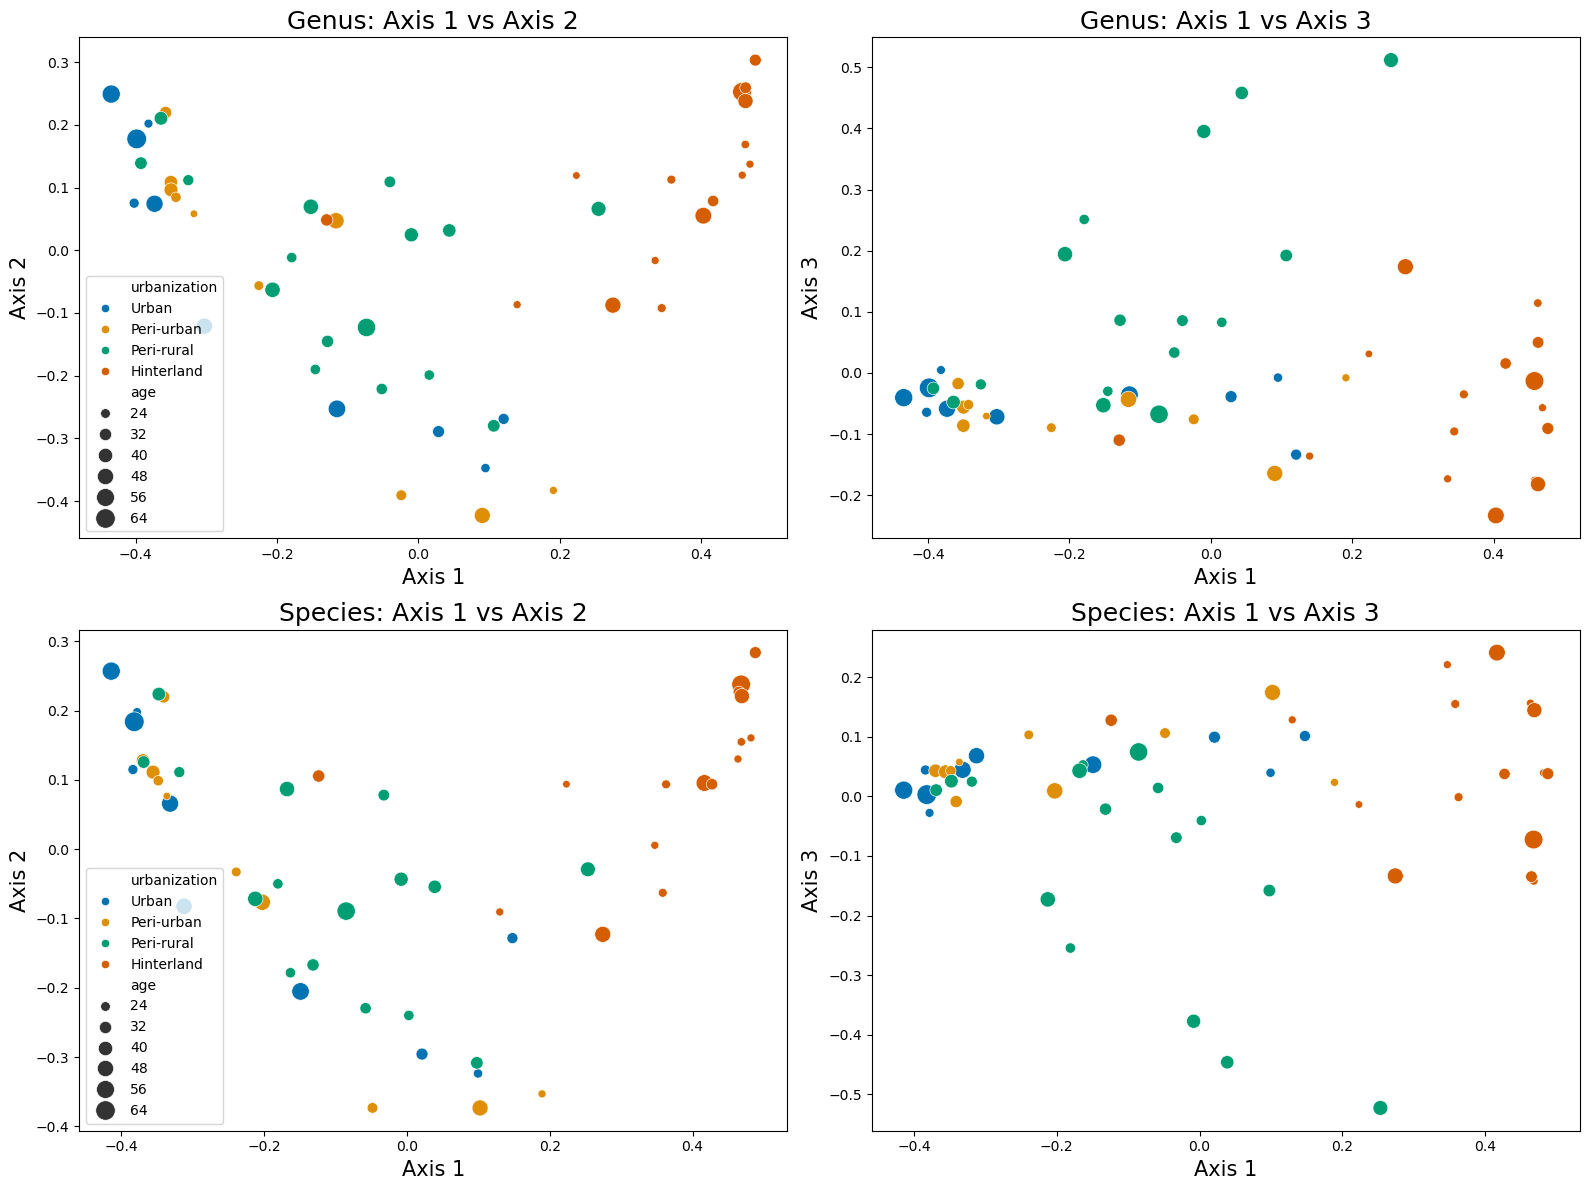

In [21]:
# PCoA scatterplots: Genus and Species
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Genus: Axis 1 vs Axis 2
sns.scatterplot(
    data=bc_md_data_G,
    x='Axis 1',
    y='Axis 2',
    hue='urbanization',
    size='age',
    palette='colorblind',
    sizes=(30, 200),
    ax=axes[0, 0]
)
axes[0, 0].set_title('Genus: Axis 1 vs Axis 2', fontsize = 18)
axes[0, 0].set_xlabel('Axis 1', fontsize=15)
axes[0, 0].set_ylabel('Axis 2', fontsize=15)

# Genus: Axis 1 vs Axis 3
sns.scatterplot(
    data=bc_md_data_G,
    x='Axis 1',
    y='Axis 3',
    hue='urbanization',
    size='age',
    palette='colorblind',
    sizes=(30, 200),
    ax=axes[0, 1],
    legend=False
)
axes[0, 1].set_title('Genus: Axis 1 vs Axis 3', fontsize = 18)
axes[0, 1].set_xlabel('Axis 1', fontsize=15)
axes[0, 1].set_ylabel('Axis 3', fontsize=15)

# Species: Axis 1 vs Axis 2
sns.scatterplot(
    data=bc_md_data_S,
    x='Axis 1',
    y='Axis 2',
    hue='urbanization',
    size='age',
    palette='colorblind',
    sizes=(30, 200),
    ax=axes[1, 0]
)
axes[1, 0].set_title('Species: Axis 1 vs Axis 2', fontsize = 18)
axes[1, 0].set_xlabel('Axis 1', fontsize=15)
axes[1, 0].set_ylabel('Axis 2', fontsize=15)

# Species: Axis 1 vs Axis 3
sns.scatterplot(
    data=bc_md_data_S,
    x='Axis 1',
    y='Axis 3',
    hue='urbanization',
    size='age',
    palette='colorblind',
    sizes=(30, 200),
    ax=axes[1, 1],
    legend=False
)
axes[1, 1].set_title('Species: Axis 1 vs Axis 3', fontsize = 18)
axes[1, 1].set_xlabel('Axis 1', fontsize=15)
axes[1, 1].set_ylabel('Axis 3', fontsize=15)

plt.tight_layout()
plt.show()

### 3.4. Jaccard Seaborn Visualisation

In [22]:
# Load PCoA results 
jac_coords_G = q2.Artifact.load(os.path.join(beta_dir, 'core-metrics-results-G/jaccard_pcoa_results.qza'))
jac_coords_G = jac_coords_G.view(OrdinationResults)

jac_coords_S = q2.Artifact.load(os.path.join(beta_dir, 'core-metrics-results-S/jaccard_pcoa_results.qza'))
jac_coords_S = jac_coords_S.view(OrdinationResults)

# Extract only first 3 axes
jac_data_G = jac_coords_G.samples.iloc[:,:3]
jac_data_S = jac_coords_S.samples.iloc[:,:3]

# Renames Columns
jac_data_G.columns = ['Axis 1', 'Axis 2', 'Axis 3']
jac_data_S.columns = ['Axis 1', 'Axis 2', 'Axis 3']

# Get Relevant metadata to add 
sample_type_df = metadata_df[["urbanization", "age", "country_iso3"]]

# Join dataframes 
jac_md_data_G = pd.concat([sample_type_df, jac_data_G], join = 'inner', axis = 1)
jac_md_data_S = pd.concat([sample_type_df, jac_data_S], join = 'inner', axis = 1)

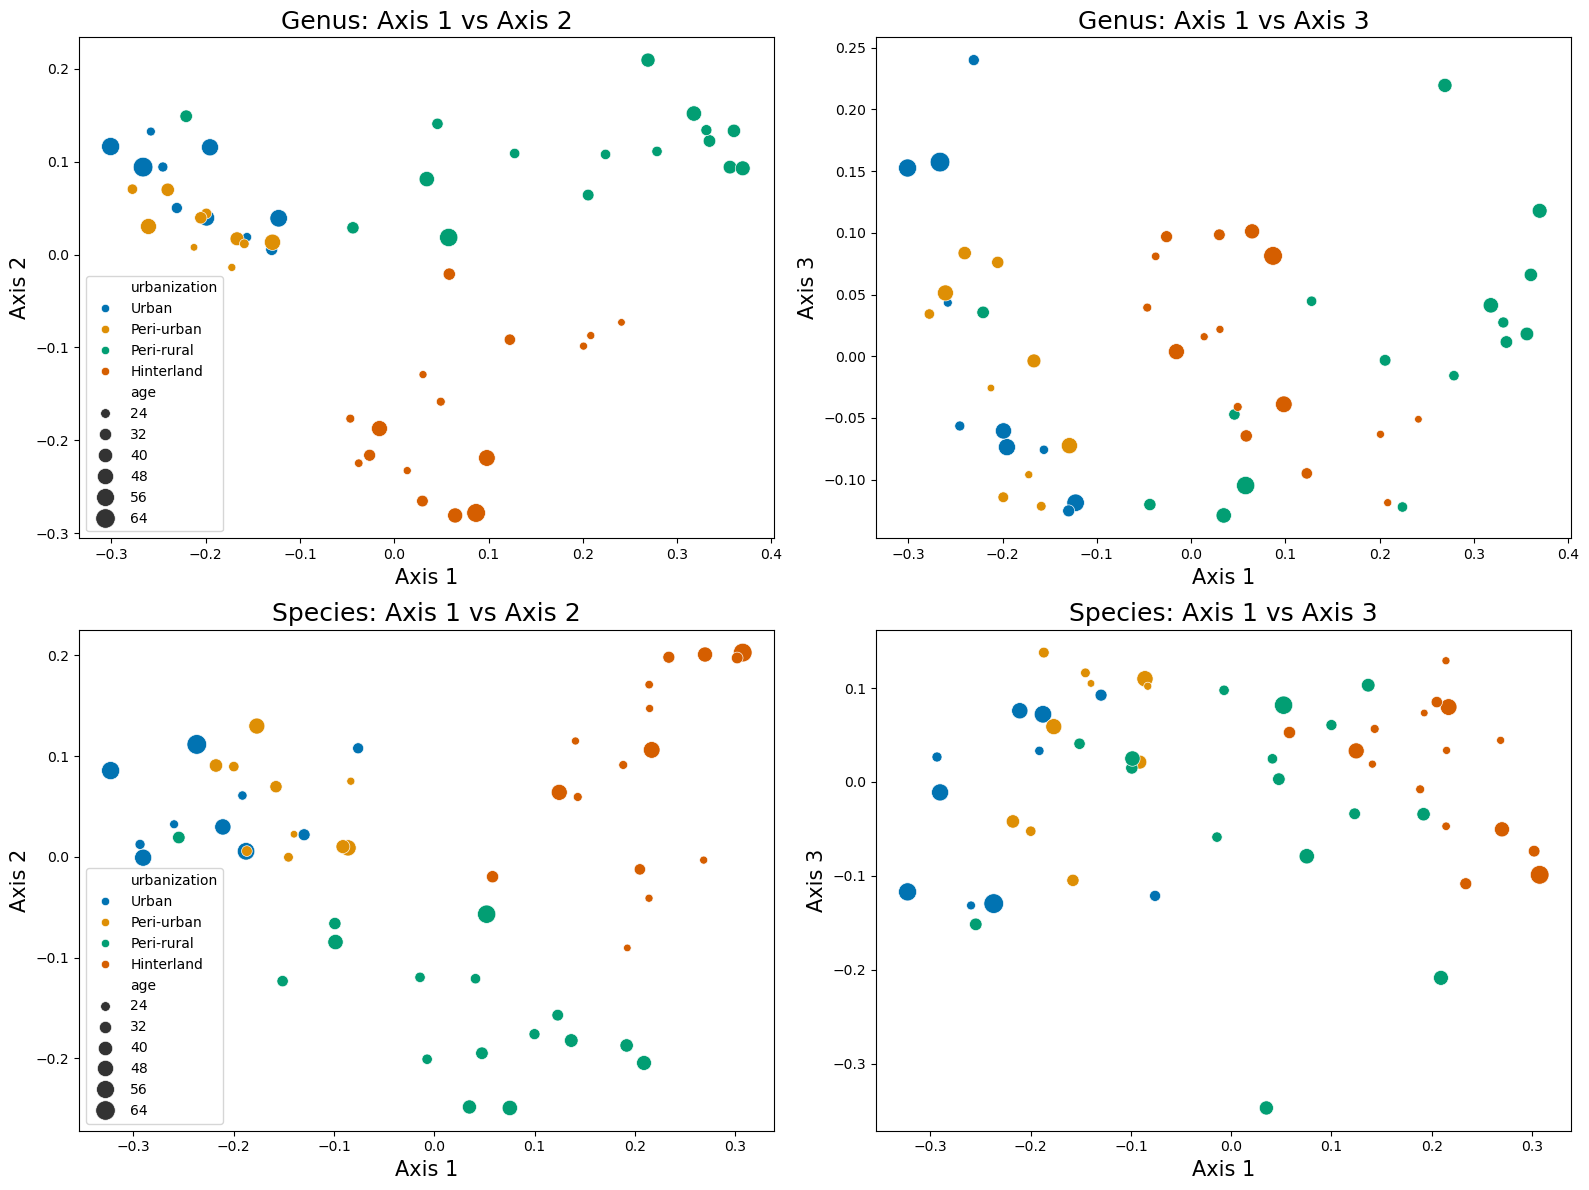

In [23]:
# PCoA scatterplots: Genus and Species
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Genus: Axis 1 vs Axis 2
sns.scatterplot(
    data=jac_md_data_G,
    x='Axis 1',
    y='Axis 2',
    hue='urbanization',
    size='age',
    palette='colorblind',
    sizes=(30, 200),
    ax=axes[0, 0]
)
axes[0, 0].set_title('Genus: Axis 1 vs Axis 2', fontsize = 18)
axes[0, 0].set_xlabel('Axis 1', fontsize=15)
axes[0, 0].set_ylabel('Axis 2', fontsize=15)

# Genus: Axis 1 vs Axis 3
sns.scatterplot(
    data=jac_md_data_G,
    x='Axis 1',
    y='Axis 3',
    hue='urbanization',
    size='age',
    palette='colorblind',
    sizes=(30, 200),
    ax=axes[0, 1],
    legend=False
)
axes[0, 1].set_title('Genus: Axis 1 vs Axis 3', fontsize = 18)
axes[0, 1].set_xlabel('Axis 1', fontsize=15)
axes[0, 1].set_ylabel('Axis 3', fontsize=15)

# Species: Axis 1 vs Axis 2
sns.scatterplot(
    data=jac_md_data_S,
    x='Axis 1',
    y='Axis 2',
    hue='urbanization',
    size='age',
    palette='colorblind',
    sizes=(30, 200),
    ax=axes[1, 0]
)
axes[1, 0].set_title('Species: Axis 1 vs Axis 2', fontsize = 18)
axes[1, 0].set_xlabel('Axis 1', fontsize=15)
axes[1, 0].set_ylabel('Axis 2', fontsize=15)

# Species: Axis 1 vs Axis 3
sns.scatterplot(
    data=jac_md_data_S,
    x='Axis 1',
    y='Axis 3',
    hue='urbanization',
    size='age',
    palette='colorblind',
    sizes=(30, 200),
    ax=axes[1, 1],
    legend=False
)
axes[1, 1].set_title('Species: Axis 1 vs Axis 3', fontsize = 18)
axes[1, 1].set_xlabel('Axis 1', fontsize=15)
axes[1, 1].set_ylabel('Axis 3', fontsize=15)

plt.tight_layout()
plt.show()

## 4. Perform PERMANOVA on Urbanization categories

#### **GENUS-LEVEL**

In [24]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix $beta_dir/core-metrics-results-G/bray_curtis_distance_matrix.qza \
        --m-metadata-file $root_dir/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-pairwise \
        --o-visualization $beta_dir/core-metrics-results-G/bray_curtis-urb-significance.qzv

In [25]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-G/bray_curtis-urb-significance.qzv")

In [26]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix {beta_dir}/core-metrics-results-G/jaccard_distance_matrix.qza \
        --m-metadata-file /home/jovyan/microbiome/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-pairwise \
        --o-visualization {beta_dir}/core-metrics-results-G/jaccard-urb-significance.qzv

In [27]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-G/jaccard-significance.qzv")

#### **SPECIES-LEVEL**

In [28]:
if rerun_analyses == True:    
    ! qiime diversity beta-group-significance \
        --i-distance-matrix $beta_dir/core-metrics-results-S/bray_curtis_distance_matrix.qza \
        --m-metadata-file $root_dir/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-pairwise \
        --o-visualization $beta_dir/core-metrics-results-S/bray_curtis-urb-significance.qzv

In [29]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-S/bray_curtis-urb-significance.qzv")

In [30]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix $beta_dir/core-metrics-results-S/jaccard_distance_matrix.qza \
        --m-metadata-file $root_dir/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-pairwise \
        --o-visualization $beta_dir/core-metrics-results-S/jaccard-urb-significance.qzv

In [31]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-S/jaccard-urb-significance.qzv")

## 5. Perform PERMDIST on Urbanisation Categories

In [32]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix {beta_dir}/core-metrics-results-G/bray_curtis_distance_matrix.qza \
        --m-metadata-file /home/jovyan/microbiome/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-method permdisp \
        --p-pairwise \
        --o-visualization {beta_dir}/core-metrics-results-G/bray_curtis-urb-permdist.qzv

In [33]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-G/bray_curtis-urb-permdist.qzv")

In [34]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix {beta_dir}/core-metrics-results-G/jaccard_distance_matrix.qza \
        --m-metadata-file /home/jovyan/microbiome/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-method permdisp \
        --p-pairwise \
        --o-visualization {beta_dir}/core-metrics-results-G/jaccard-urb-permdist.qzv

In [35]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-G/jaccard-urb-permdist.qzv")

In [36]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix {beta_dir}/core-metrics-results-S/bray_curtis_distance_matrix.qza \
        --m-metadata-file /home/jovyan/microbiome/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-method permdisp \
        --p-pairwise \
        --o-visualization {beta_dir}/core-metrics-results-S/bray_curtis-urb-permdist.qzv

In [37]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-S/bray_curtis-urb-permdist.qzv")

In [38]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix {beta_dir}/core-metrics-results-S/jaccard_distance_matrix.qza \
        --m-metadata-file /home/jovyan/microbiome/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-method permdisp \
        --p-pairwise \
        --o-visualization {beta_dir}/core-metrics-results-S/jaccard-urb-permdist.qzv

In [39]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-S/jaccard-urb-permdist.qzv")

## 6. Perform ANOSIM Analysis on Urbanisation Categories 

In [40]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix {beta_dir}/core-metrics-results-G/bray_curtis_distance_matrix.qza \
        --m-metadata-file /home/jovyan/microbiome/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-method anosim \
        --p-pairwise \
        --o-visualization {beta_dir}/core-metrics-results-G/bray_curtis-urb-anosim.qzv

In [41]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-G/bray_curtis-urb-anosim.qzv")

In [42]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix {beta_dir}/core-metrics-results-G/jaccard_distance_matrix.qza \
        --m-metadata-file /home/jovyan/microbiome/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-method anosim \
        --p-pairwise \
        --o-visualization {beta_dir}/core-metrics-results-G/jaccard-urb-anosim.qzv

In [43]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-G/jaccard-urb-anosim.qzv")

In [44]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix {beta_dir}/core-metrics-results-S/bray_curtis_distance_matrix.qza \
        --m-metadata-file /home/jovyan/microbiome/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-method anosim \
        --p-pairwise \
        --o-visualization {beta_dir}/core-metrics-results-S/bray_curtis-urb-anosim.qzv

In [45]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-S/bray_curtis-urb-anosim.qzv")

In [46]:
if rerun_analyses == True:
    ! qiime diversity beta-group-significance \
        --i-distance-matrix {beta_dir}/core-metrics-results-S/jaccard_distance_matrix.qza \
        --m-metadata-file /home/jovyan/microbiome/african_gut_microbiomes_metadata.tsv \
        --m-metadata-column urbanization \
        --p-method anosim \
        --p-pairwise \
        --o-visualization {beta_dir}/core-metrics-results-S/jaccard-urb-anosim.qzv

In [47]:
if visualise == True:
    Visualization.load(f"{beta_dir}/core-metrics-results-S/jaccard-urb-anosim.qzv")